In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pylab as plt 
import seaborn as sns 

Matplotlib is building the font cache; this may take a moment.


In [13]:
df = pd.read_csv('../data/processed/data.csv')
df.shape

(1187, 33)

In [14]:
df.head(10)

,DATE,OPEN,HIGH,LOW,CLOSE,VOLUME,LABEL,PCT_CHANGE,PCT_CHANGE_5D,SMA_5,...,BB_UPPER,BB_LOWER,BB_WIDTH,BB_PCT_B,VOLATILITY_10,VOLATILITY_20,HIGH_LOW_RANGE,VOLUME_CHANGE,VOLUME_SMA_10,VOLUME_RATIO
0,2021-11-12,1287.60,1305.61,1284.64,1302.77,8003073.0,0,1.51,3.77,1278.226,...,1381.093611,1224.226389,0.120421,0.500701,1.199363,1.293394,0.016096,-18.746948,10994271.6,0.727931
1,2021-11-15,1306.24,1307.35,1291.17,1295.09,4412237.0,0,-0.59,3.03,1285.848,...,1373.807289,1225.353711,0.114232,0.469751,0.898434,1.293112,0.012493,-44.868215,10128063.2,0.435645
2,2021-11-16,1292.20,1293.68,1253.49,1264.99,10414594.0,0,-2.32,-0.15,1285.466,...,1364.741461,1224.888539,0.108010,0.286740,1.195473,1.368576,0.031771,136.038862,9747442.2,1.068444
3,2021-11-17,1255.47,1255.47,1236.41,1237.91,9371487.0,1,-2.14,-3.37,1276.834,...,1352.203161,1223.969839,0.099553,0.108709,1.298071,1.390727,0.015397,-10.015820,9713720.7,0.964768
4,2021-11-18,1235.90,1250.47,1230.91,1242.59,7813187.0,0,0.38,-3.18,1268.670,...,1340.855623,1223.908377,0.091195,0.159744,1.291874,1.395452,0.015741,-16.628098,9393701.8,0.831747
5,2021-11-22,1223.90,1230.38,1181.14,1187.55,22160358.0,1,-4.43,-8.84,1245.626,...,1345.699079,1206.065921,0.109440,-0.132604,1.867570,1.570794,0.041464,183.627641,11453057.7,1.934886
6,2021-11-23,1172.12,1206.39,1160.04,1198.65,23265139.0,0,0.93,-7.45,1226.338,...,1344.414338,1195.214662,0.117497,0.023025,1.916212,1.596555,0.038669,4.985393,11911417.3,1.953180
7,2021-11-24,1195.71,1210.73,1177.40,1181.34,15450963.0,1,-1.44,-6.61,1209.608,...,1345.702301,1181.346699,0.130077,-0.000041,1.884463,1.607737,0.028214,-33.587489,12015934.4,1.285873
8,2021-11-25,1192.20,1257.00,1184.23,1252.46,38950014.0,0,6.02,1.18,1212.518,...,1333.935221,1184.668779,0.118531,0.454163,2.812863,2.091815,0.058102,152.087938,14969061.8,2.602034
9,2021-11-26,1239.82,1244.75,1206.51,1212.09,14479869.0,1,-3.22,-2.45,1206.418,...,1325.606010,1182.205990,0.114363,0.208396,2.964565,2.182819,0.031549,-62.824483,15432092.1,0.938296


In [ ]:
df.dtypes

DATE                  str
OPEN              float64
HIGH              float64
LOW               float64
CLOSE             float64
VOLUME            float64
LABEL               int64
PCT_CHANGE        float64
PCT_CHANGE_5D     float64
SMA_5             float64
SMA_10            float64
SMA_20            float64
SMA_50            float64
CLOSE_TO_SMA5     float64
CLOSE_TO_SMA10    float64
CLOSE_TO_SMA20    float64
CLOSE_TO_SMA50    float64
EMA_12            float64
EMA_26            float64
MACD_LINE         float64
MACD_SIGNAL       float64
MACD_HIST         float64
RSI_14            float64
BB_UPPER          float64
BB_LOWER          float64
BB_WIDTH          float64
BB_PCT_B          float64
VOLATILITY_10     float64
VOLATILITY_20     float64
HIGH_LOW_RANGE    float64
VOLUME_CHANGE     float64
VOLUME_SMA_10     float64
VOLUME_RATIO      float64
dtype: object

Text(0, 0.5, 'Count')

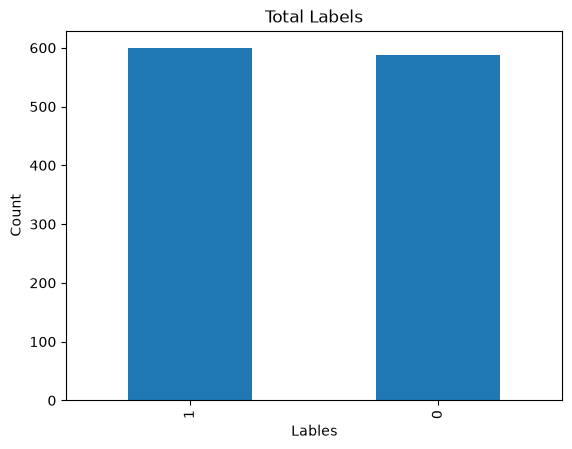

In [32]:
label_count = df['LABEL'].value_counts() \
    .plot(kind='bar', title='Total Labels')
label_count.set_xlabel("Lables")
label_count.set_ylabel("Count")

Text(0, 0.5, 'FREQUENCY')

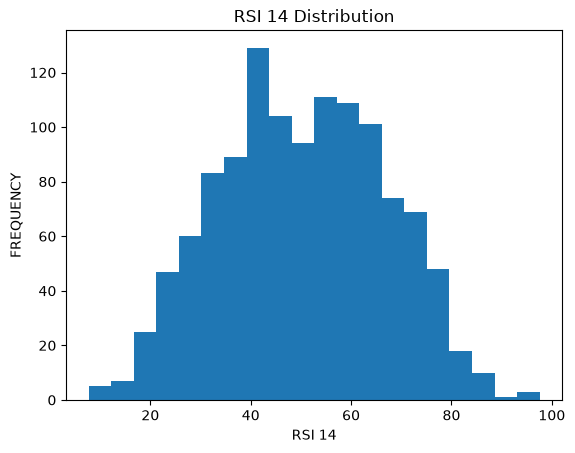

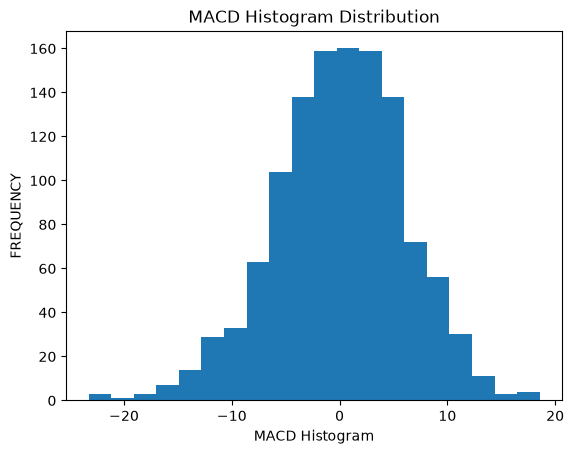

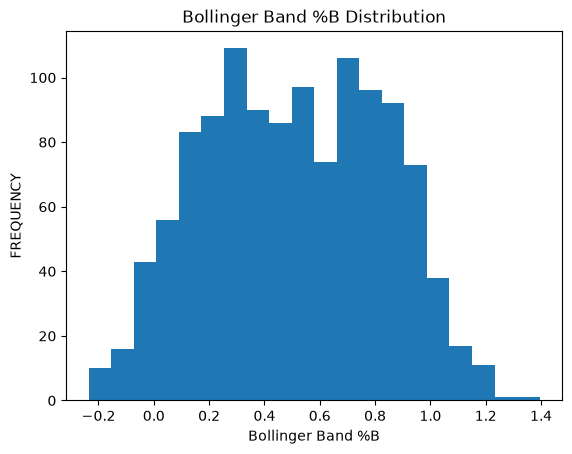

In [45]:
# RSI 14
plt.figure()
rsi_14_hist = df["RSI_14"].plot(kind="hist", bins=20, title="RSI 14 Distribution")
rsi_14_hist.set_xlabel("RSI 14")
rsi_14_hist.set_ylabel("FREQUENCY")

# MACD Histogram
plt.figure()
macd_hist = df["MACD_HIST"].plot(kind="hist", bins=20, title="MACD Histogram Distribution")
macd_hist.set_xlabel("MACD Histogram")
macd_hist.set_ylabel("FREQUENCY")

# Bollinger Band %B
plt.figure()
bb_pct_b_hist = df["BB_PCT_B"].plot(kind="hist", bins=20, title="Bollinger Band %B Distribution")
bb_pct_b_hist.set_xlabel("Bollinger Band %B")
bb_pct_b_hist.set_ylabel("FREQUENCY")

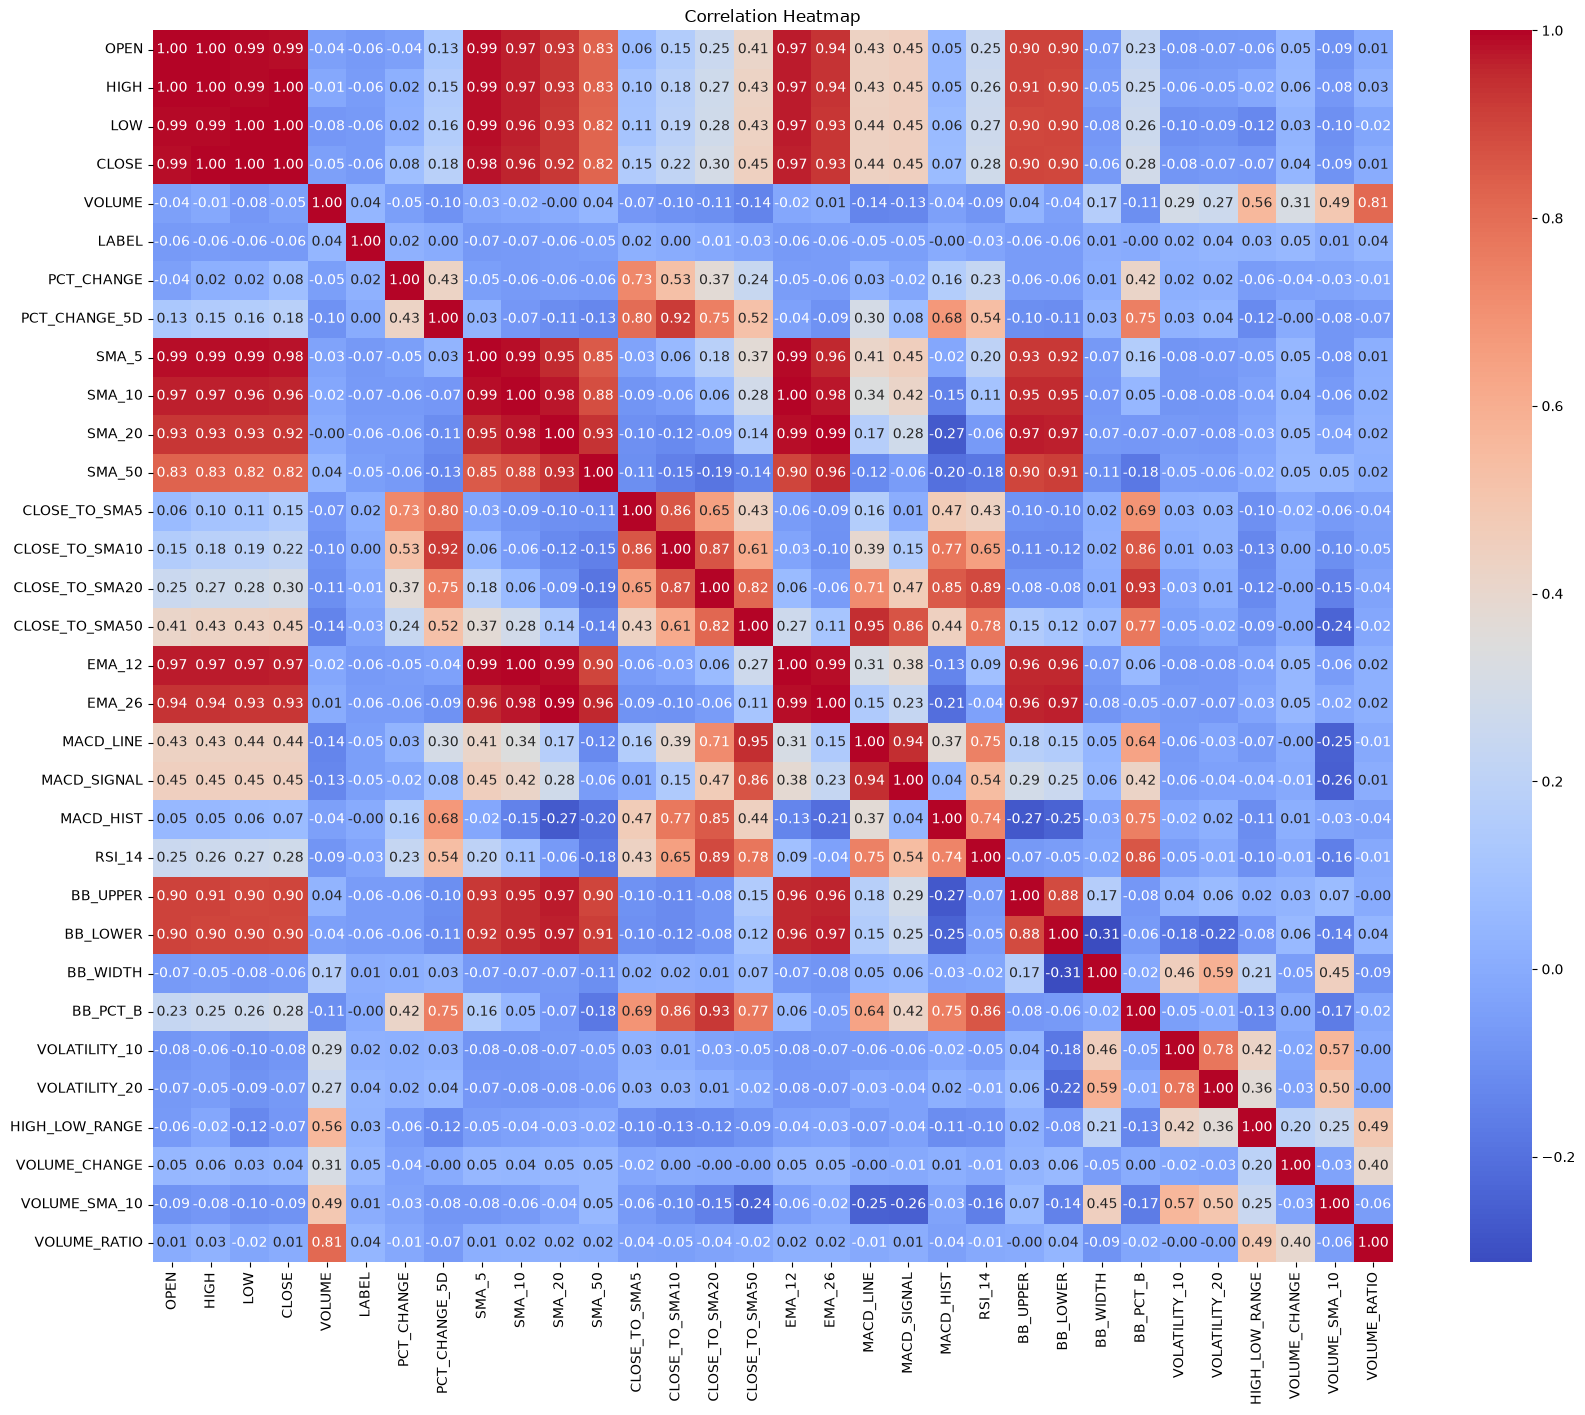

In [48]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(20, 16))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

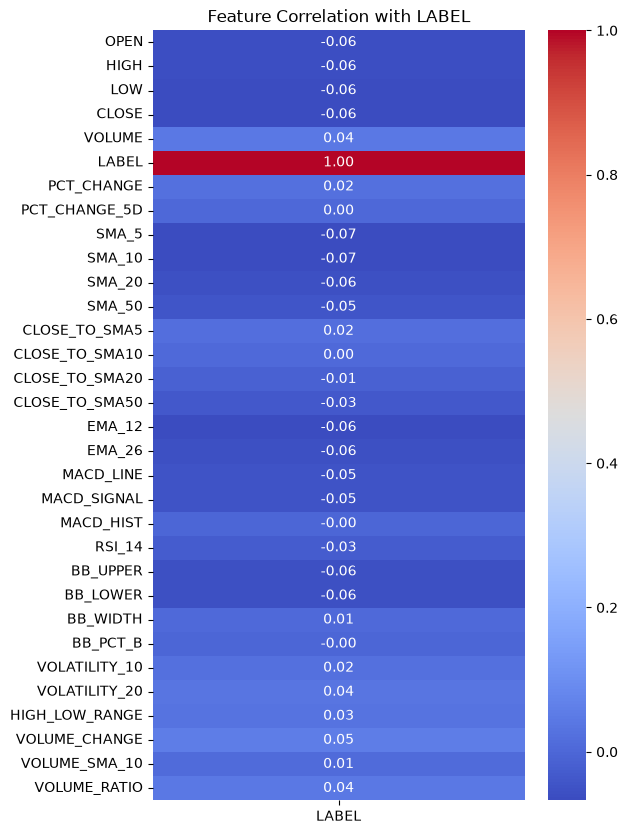

In [49]:
label_corr = df.corr(numeric_only=True)[["LABEL"]]

plt.figure(figsize=(6, 10))

sns.heatmap(
    label_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation with LABEL")
plt.show()

In [50]:
df.isna().sum().sum()

np.int64(0)